In [2]:
%pip install datasets tensorflow numpy pandas scikit-learn seqeval matplotlib

  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Installing backend dependencies: started
  Installing backend dependencies: still running...
  Installing backend dependencies: still running...
  Installing backend dependencies: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
  Created wheel for seqeval: filename=seqeval-1.2.2-py3-none-any.whl size=16282 sha256=4512027fb4d0c740d4911274395ed724196b31f5eca9845a294f54b85a931bf7
  Stored in directory: c:\users\hp\appdata\local\pip\cache\wheels\14\cf\a7\8f28ef376d707ff10e3922899482a2f23ef3002f8a952f47ac
Successfully built seqeval
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import numpy as np
import pandas as pd
import pickle
import json
import matplotlib.pyplot as plt

from datasets import load_dataset

from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import (
    Embedding,
    Bidirectional,
    LSTM,
    Dense,
    Dropout,
    Input
)

from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

from seqeval.metrics import (
    classification_report,
    f1_score,
    precision_score,
    recall_score
)

In [4]:
dataset = load_dataset("BramVanroy/conll2003")

c:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\HP\.cache\huggingface\hub\datasets--BramVanroy--conll2003. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
c:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\huggingface_hub\file_downlo

In [5]:
dataset

DatasetDict({
    train: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'chunk_tags', 'ner_tags'],
        num_rows: 14041
    })
    validation: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'chunk_tags', 'ner_tags'],
        num_rows: 3250
    })
    test: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'chunk_tags', 'ner_tags'],
        num_rows: 3453
    })
})

In [12]:
train_data = dataset["train"]
val_data = dataset["validation"]
test_data = dataset["test"]

In [13]:
train_data

Dataset({
    features: ['id', 'tokens', 'pos_tags', 'chunk_tags', 'ner_tags'],
    num_rows: 14041
})

In [14]:
print("Training:", len(train_data))
print("Validation:", len(val_data))
print("Testing:", len(test_data))

Training: 14041
Validation: 3250
Testing: 3453


In [15]:
print("Tokens:")
print(train_data[0]["tokens"])

print("\nNER Tags:")
print(train_data[0]["ner_tags"])

Tokens:
['EU', 'rejects', 'German', 'call', 'to', 'boycott', 'British', 'lamb', '.']

NER Tags:
[3, 0, 7, 0, 0, 0, 7, 0, 0]


In [16]:
label_names = [
    "O",
    "B-PER",
    "I-PER",
    "B-ORG",
    "I-ORG",
    "B-LOC",
    "I-LOC",
    "B-MISC",
    "I-MISC"
]

NUM_CLASSES = len(label_names)

print(label_names)
print("Total Classes:", NUM_CLASSES)

['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']
Total Classes: 9


In [28]:
from collections import Counter

In [30]:
word_counts=Counter()
for sentence in train_data["tokens"]:
    word_counts.update(sentence)
word2idex={
    "<PAD>":0,
    "<UNK>":1
}
for word,count in word_counts.items():
    word2idex[word]=len(word2idex)
idx2word={
    index:word
    for word,index in word2idex.items()
}
VOCAB_SIZE = len(word2idx)

print("Vocabulary Size:", VOCAB_SIZE)

Vocabulary Size: 23625


In [34]:
MAX_LEn=120
def convert_data(data):
    X=[]
    y=[]
    for sentence,tags in zip(data["tokens"],data["ner_tags"]):
        word_ids=[word2idex.get(word,word2idex["<UNK>"]) for word in sentence]
        X.append(word_ids)
        y.append(tags)
    X = pad_sequences(X,maxlen=MAX_LEN,padding="post",truncating="post",value=0 )
    y = pad_sequences(y,maxlen=MAX_LEN,padding="post",truncating="post",value=0)
    return X, y
        

In [ ]:
X_train, y_train = convert_data(train_data)

X_val, y_val = convert_data(val_data)

X_test, y_test = convert_data(test_data)

print("X Train:", X_train.shape)
print("Y Train:", y_train.shape)

print("X Validation:", X_val.shape)
print("Y Validation:", y_val.shape)

print("X Test:", X_test.shape)
print("Y Test:", y_test.shape)

X Train: (14041, 120)
Y Train: (14041, 120)
X Validation: (3250, 120)
Y Validation: (3250, 120)
X Test: (3453, 120)
Y Test: (3453, 120)


In [36]:
train_weights = (X_train != 0).astype("float32")
val_weights = (X_val != 0).astype("float32")
test_weights = (X_test != 0).astype("float32")

In [ ]:
model = Sequential([
    Input(shape=(MAX_LEN,)),
    Embedding(
        input_dim=VOCAB_SIZE,
        output_dim=128,
        mask_zero=True
    ),
    Bidirectional(
        LSTM(
            64,
            return_sequences=True
        )
    ),
    Dropout(0.3),
    Bidirectional(
        LSTM(
            32,
            return_sequences=True
        )
    ),
    Dropout(0.3),
    Dense(
        NUM_CLASSES,
        activation="softmax"
    )
])

model.summary()

In [37]:
model.compile(

    optimizer="adam",

    loss="sparse_categorical_crossentropy",

    weighted_metrics=["accuracy"]
)

In [38]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

checkpoint = ModelCheckpoint(
    "Best_NER_Model.keras",
    monitor="val_loss",
    save_best_only=True
)

history = model.fit(

    X_train,
    y_train,

    validation_data=(
        X_val,
        y_val,
        val_weights
    ),

    sample_weight=train_weights,

    epochs=15,

    batch_size=64,

    callbacks=[
        early_stop,
        checkpoint
    ]
)

Epoch 1/15
220/220 ━━━━━━━━━━━━━━━━━━━━ 137s 508ms/step - accuracy: 0.8673 - loss: 0.4467 - val_accuracy: 0.9098 - val_loss: 0.3152
Epoch 2/15
220/220 ━━━━━━━━━━━━━━━━━━━━ 107s 487ms/step - accuracy: 0.9428 - loss: 0.1816 - val_accuracy: 0.9421 - val_loss: 0.2049
Epoch 3/15
220/220 ━━━━━━━━━━━━━━━━━━━━ 97s 439ms/step - accuracy: 0.9770 - loss: 0.0875 - val_accuracy: 0.9512 - val_loss: 0.1775
Epoch 4/15
220/220 ━━━━━━━━━━━━━━━━━━━━ 147s 461ms/step - accuracy: 0.9890 - loss: 0.0484 - val_accuracy: 0.9553 - val_loss: 0.1701
Epoch 5/15
220/220 ━━━━━━━━━━━━━━━━━━━━ 123s 559ms/step - accuracy: 0.9925 - loss: 0.0335 - val_accuracy: 0.9550 - val_loss: 0.1734
Epoch 6/15
220/220 ━━━━━━━━━━━━━━━━━━━━ 101s 459ms/step - accuracy: 0.9942 - loss: 0.0253 - val_accuracy: 0.9567 - val_loss: 0.1761
Epoch 7/15
220/220 ━━━━━━━━━━━━━━━━━━━━ 105s 478ms/step - accuracy: 0.9955 - loss: 0.0195 - val_accuracy: 0.9601 - val_loss: 0.1698
Epoch 8/15
220/220 ━━━━━━━━━━━━━━━━━━━━ 123s 560ms/step - accuracy: 0.9961 - 

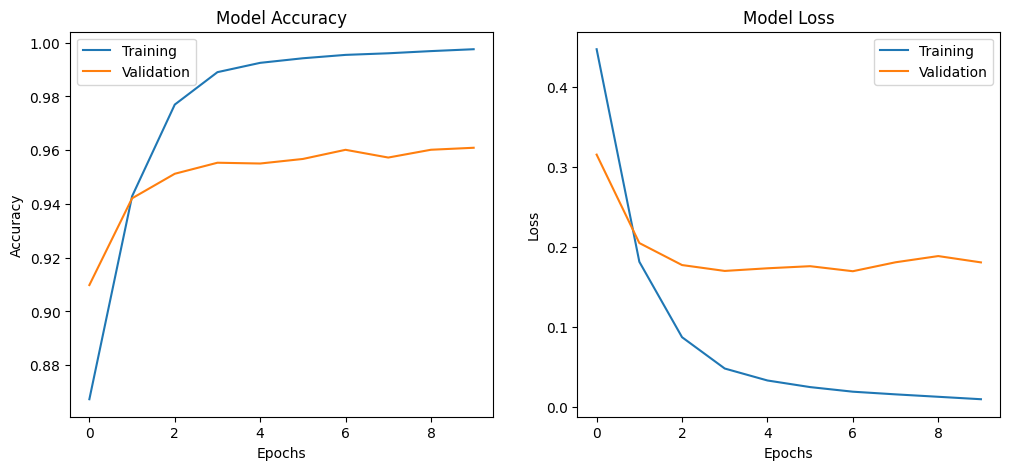

In [39]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.plot(history.history["accuracy"])
plt.plot(history.history["val_accuracy"])

plt.title("Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")

plt.legend(["Training", "Validation"])


plt.subplot(1, 2, 2)

plt.plot(history.history["loss"])
plt.plot(history.history["val_loss"])

plt.title("Model Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")

plt.legend(["Training", "Validation"])

plt.show()

In [40]:
model = load_model("Best_NER_Model.keras")

In [41]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    sample_weight=test_weights
)

print("Test Loss:", test_loss)
print("Test Token Accuracy:", test_accuracy)

108/108 ━━━━━━━━━━━━━━━━━━━━ 18s 110ms/step - accuracy: 0.9383 - loss: 0.2760
Test Loss: 0.27601704001426697
Test Token Accuracy: 0.9383170008659363


In [42]:
def predict_ner(sentence):

    words = sentence.split()

    word_ids = [
        word2idx.get(word, word2idx["<UNK>"])
        for word in words
    ]

    padded = pad_sequences(
        [word_ids],
        maxlen=MAX_LEN,
        padding="post",
        truncating="post"
    )

    prediction = model.predict(
        padded,
        verbose=0
    )

    predicted_ids = np.argmax(
        prediction[0],
        axis=-1
    )

    results = []

    for word, tag_id in zip(
        words[:MAX_LEN],
        predicted_ids[:MAX_LEN]
    ):

        tag = label_names[tag_id]

        results.append({
            "Word": word,
            "Entity": tag
        })

    return pd.DataFrame(results)

In [43]:
sentence = "Barack Obama visited London and met Microsoft employees"

result = predict_ner(sentence)

print(result)

        Word Entity
0     Barack  B-ORG
1      Obama  I-ORG
2    visited      O
3     London  B-ORG
4        and      O
5        met      O
6  Microsoft  B-ORG
7  employees      O


In [46]:
model.save("NER_BiLSTM.keras")

with open("NER_word2idx.pkl", "wb") as file:

    pickle.dump(word2idx, file)

with open("NER_label_names.json", "w") as file:

    json.dump(label_names, file)

print("Model and vocabulary saved successfully!")

Model and vocabulary saved successfully!
